In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q ultralytics
!cp /content/drive/MyDrive/garbage_project/dataset_final.zip /content/
!unzip -q -o /content/dataset_final.zip -d /content

# data.yaml was saved with absolute paths, so it works as is
!ls /content/dataset_final

from ultralytics import YOLO
BEST = '/content/drive/MyDrive/garbage_project/best_v8m_640.pt'
model = YOLO(BEST)
print(model.names)

In [1]:
!nvidia-smi
!pip install -q ultralytics roboflow
import ultralytics; ultralytics.checks()

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.4/112.6 GB disk)


In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/garbage_project_42'
os.makedirs(PROJECT_DIR, exist_ok=True)

Mounted at /content/drive


In [3]:
from google.colab import drive
drive.mount('/content/drive')
!cp "/content/drive/MyDrive/Dataset New.zip" /content/
!ls -lh /content/*.zip

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
-rw------- 1 root root 124M Oct  9 02:58 '/content/Dataset New.zip'


In [4]:
import os
PROJECT_DIR = '/content/garbage_project'
os.makedirs(PROJECT_DIR, exist_ok=True)

!pip install -q ultralytics

In [5]:
import glob, shutil, zipfile, os

zips = glob.glob('/content/*.zip')
print('Zip files found:', zips)
ZIP_PATH = zips[0]          # if you have more than one zip, put the exact path here

shutil.rmtree('/content/_tmp', ignore_errors=True)
with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall('/content/_tmp')

yaml_files = glob.glob('/content/_tmp/**/data.yaml', recursive=True)
print('data.yaml found at:', yaml_files)
root = os.path.dirname(yaml_files[0])

shutil.rmtree('/content/dataset', ignore_errors=True)
shutil.move(root, '/content/dataset')
print(os.listdir('/content/dataset'))

Zip files found: ['/content/Dataset New.zip']
data.yaml found at: ['/content/_tmp/data.yaml']
['valid', 'README.roboflow.txt', 'data.yaml', 'test', 'train', 'README.dataset.txt']


In [6]:
import yaml, glob, os

DATA = '/content/dataset'
cfg = yaml.safe_load(open(f'{DATA}/data.yaml'))
names = cfg['names']
NAMES = [names[i] for i in sorted(names)] if isinstance(names, dict) else list(names)
print('Number of classes:', len(NAMES))

VAL = 'valid' if os.path.isdir(f'{DATA}/valid') else 'val'

new_cfg = {'path': DATA, 'train': 'train/images', 'val': f'{VAL}/images',
    'nc': len(NAMES), 'names': NAMES}
if os.path.isdir(f'{DATA}/test'):
   new_cfg['test'] = 'test/images'
yaml.dump(new_cfg, open(f'{DATA}/data.yaml', 'w'), sort_keys=False)

for s in ['train', VAL, 'test']:
    print(s, len(glob.glob(f'{DATA}/{s}/images/*')), 'images')

Number of classes: 42
train 3822 images
valid 1092 images
test 546 images


 id class                                train   val
  2 Aluminum caps                            0     1  <-- RARE
  6 Combined plastic                         0     4  <-- RARE
 10 Foil                                     0     0  <-- RARE
 13 Iron utensils                            0     2  <-- RARE
 15 Metal shavings                           0     1  <-- RARE
 40 Wood                                     0     2  <-- RARE
  4 Cellulose                                1     0  <-- RARE
 11 Furniture                                1     0  <-- RARE
  5 Ceramic                                  2     0  <-- RARE
 27 Plastic caps                             3     0  <-- RARE
 35 Stretch film                             3     0  <-- RARE
  9 Electronics                              4     0  <-- RARE
 31 Plastic toys                             4     0  <-- RARE
 34 Scrap metal                              4     0  <-- RARE
  8 Disposable tableware                     5     0  <-- RARE
 2

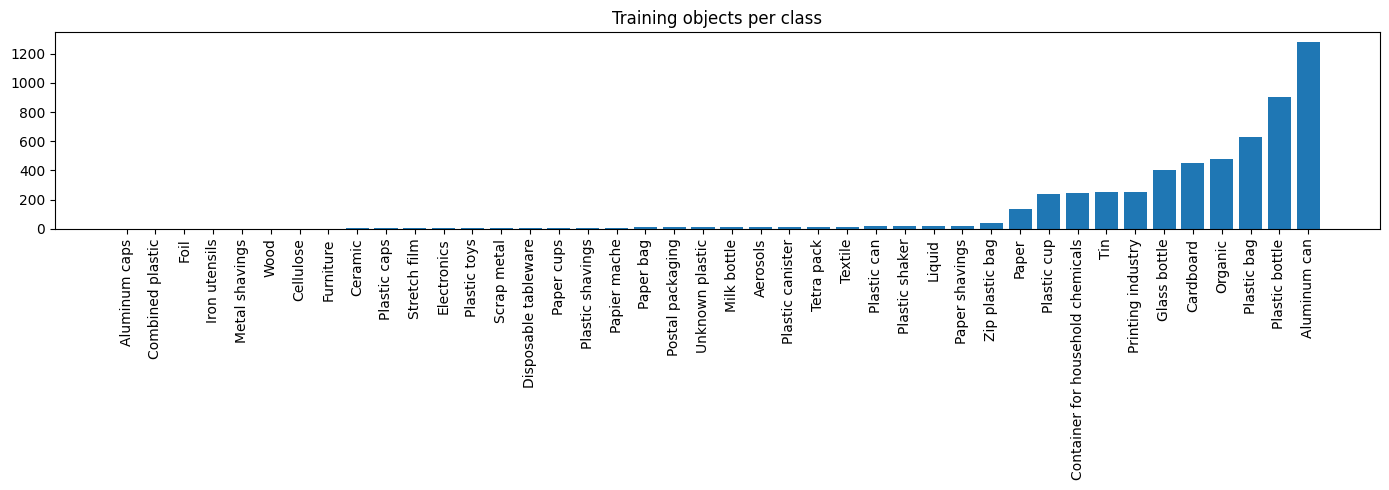

In [7]:
from collections import Counter
import matplotlib.pyplot as plt

def distribution(split):
    c = Counter()
    for f in glob.glob(f'{DATA}/{split}/labels/*.txt'):
        for line in open(f):
            p = line.split()
            if len(p) >= 5:
                c[int(p[0])] += 1
    return c

tr = distribution('train')
va = distribution(VAL)

order = sorted(range(len(NAMES)), key=lambda c: tr[c])
print(f"{'id':>3} {'class':35s} {'train':>6} {'val':>5}")
for c in order:
    flag = '  <-- RARE' if tr[c] < 100 else ''
    print(f'{c:3d} {NAMES[c]:35s} {tr[c]:6d} {va[c]:5d}{flag}')

plt.figure(figsize=(14, 5))
plt.bar([NAMES[c] for c in order], [tr[c] for c in order])
plt.xticks(rotation=90); plt.title('Training objects per class')
plt.tight_layout(); plt.show()

In [8]:
import os, shutil, yaml
from collections import Counter

MIN_TRAIN_OBJECTS = 100
MERGE = {
    'Zip plastic bag': 'Plastic bag',
    'Paper bag': 'Paper',
    'Paper shavings': 'Paper',
    'Cellulose': 'Paper',
}

# Final class list
final_name = {c: MERGE.get(NAMES[c], NAMES[c]) for c in range(len(NAMES))}
merged_count = Counter()
for c in range(len(NAMES)):
    merged_count[final_name[c]] += tr[c]

keep_names = []
for n in dict.fromkeys(final_name.values()):
    if merged_count[n] >= MIN_TRAIN_OBJECTS:
        keep_names.append(n)

new_id = {n: i for i, n in enumerate(keep_names)}
old2new = {}
for c in range(len(NAMES)):
    if final_name[c] in new_id:
        old2new[c] = new_id[final_name[c]]

print(len(NAMES), 'classes ->', len(keep_names), 'classes')
print('Kept:', keep_names)

EXTS = ['.jpg', '.jpeg', '.png', '.JPG', '.JPEG', '.PNG']

def find_image(img_dir, stem):
    for e in EXTS:
        p = img_dir + '/' + stem + e
        if os.path.exists(p):
            return p
    return None

# Build new dataset
OUT = '/content/dataset_final'
shutil.rmtree(OUT, ignore_errors=True)

for split in ['train', VAL, 'test']:
    lbl_dir = DATA + '/' + split + '/labels'
    img_dir = DATA + '/' + split + '/images'
    if not os.path.isdir(lbl_dir):
        continue
    os.makedirs(OUT + '/' + split + '/images', exist_ok=True)
    os.makedirs(OUT + '/' + split + '/labels', exist_ok=True)
    n = 0
    for f in os.listdir(lbl_dir):
        if not f.endswith('.txt'):
            continue
        new = []
        for line in open(lbl_dir + '/' + f):
            p = line.split()
            if len(p) == 5 and int(p[0]) in old2new:
                p[0] = str(old2new[int(p[0])])
                new.append(' '.join(p))
        if not new:
            continue
        stem = os.path.splitext(f)[0]
        img = find_image(img_dir, stem)
        if img is None:
            continue
        shutil.copy2(img, OUT + '/' + split + '/images/')
        with open(OUT + '/' + split + '/labels/' + f, 'w') as out_f:
            out_f.write('\n'.join(new) + '\n')
        n += 1
    print(split, n, 'images')

yaml.dump({'path': OUT, 'train': 'train/images', 'val': VAL + '/images', 'test': 'test/images',
           'nc': len(keep_names), 'names': keep_names},
          open(OUT + '/data.yaml', 'w'), sort_keys=False)
print('Done')

42 classes -> 11 classes
Kept: ['Aluminum can', 'Cardboard', 'Paper', 'Container for household chemicals', 'Glass bottle', 'Organic', 'Plastic bag', 'Plastic bottle', 'Plastic cup', 'Printing industry', 'Tin']
train 3728 images
valid 1064 images
test 533 images
Done


In [9]:
from ultralytics import YOLO

model = YOLO('yolov8m.pt')
model.train(
    data='/content/dataset_final/data.yaml',
    epochs=80,
    imgsz=640,
    batch=16,
    patience=20,
    cos_lr=True,
    close_mosaic=10,
    workers=2,
    project='/content/garbage_project',
    name='v8m_final',
    exist_ok=True,
    plots=True,
)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/dataset_final/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=v8m_final, nbs=64, nms=None, opset=None, optimize=False, op

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x786c3e4dff50>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.

In [10]:
import os, shutil
os.makedirs('/content/drive/MyDrive/garbage_project/backup', exist_ok=True)
shutil.copytree('/content/garbage_project/v8m_final',
                '/content/drive/MyDrive/garbage_project/backup/v8m_final',
                dirs_exist_ok=True)
print('Saved to Drive')

from google.colab import files
files.download('/content/garbage_project/v8m_final/weights/best.pt')

Saved to Drive


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
import os
print(os.listdir('/content/drive/MyDrive/garbage_project/backup/v8m_final/weights'))

['last.pt', 'best.pt']


In [13]:
import pandas as pd
df = pd.read_csv('/content/garbage_project/v8m_final/results.csv')
df.columns = [c.strip() for c in df.columns]
print('Epochs completed:', len(df))
print('Best mAP50:', round(df['metrics/mAP50(B)'].max(), 3))

Epochs completed: 70
Best mAP50: 0.797


In [14]:
import pandas as pd
from ultralytics import YOLO

BEST = '/content/garbage_project/v8m_final/weights/best.pt'
model = YOLO(BEST)
m = model.val(data='/content/dataset_final/data.yaml', imgsz=640)

print('Overall mAP50 =', round(m.box.map50, 3), ' mAP50-95 =', round(m.box.map, 3))
rows = []
for k, c in enumerate(m.box.ap_class_index):
    rows.append({'class': model.names[int(c)], 'P': round(m.box.p[k], 2),
                 'R': round(m.box.r[k], 2), 'mAP50': round(m.box.ap50[k], 2)})
pd.DataFrame(rows).sort_values('mAP50')

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 92 layers, 25,846,129 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 783.3±677.4 MB/s, size: 27.6 KB)
val: Scanning /content/dataset_final/valid/labels.cache... 1064 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1064/1064 262.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 67/67 2.4it/s 27.9s
                   all       1064       1511      0.773      0.741      0.789      0.587
          Aluminum can        307        404      0.925      0.913      0.942      0.635
             Cardboard        107        133      0.765       0.71      0.783      0.583
                 Paper         33         33      0.926       0.76      0.835      0.702
Container for household chemicals         34         66       0.51      0.621      0.584      0.363
          Glass bottle   

,class,P,R,mAP50
3,Container for household chemicals,0.51,0.62,0.58
6,Plastic bag,0.67,0.53,0.62
7,Plastic bottle,0.69,0.66,0.69
10,Tin,0.63,0.65,0.71
5,Organic,0.83,0.73,0.76
1,Cardboard,0.76,0.71,0.78
2,Paper,0.93,0.76,0.84
8,Plastic cup,0.74,0.88,0.87
4,Glass bottle,0.87,0.76,0.90
0,Aluminum can,0.93,0.91,0.94


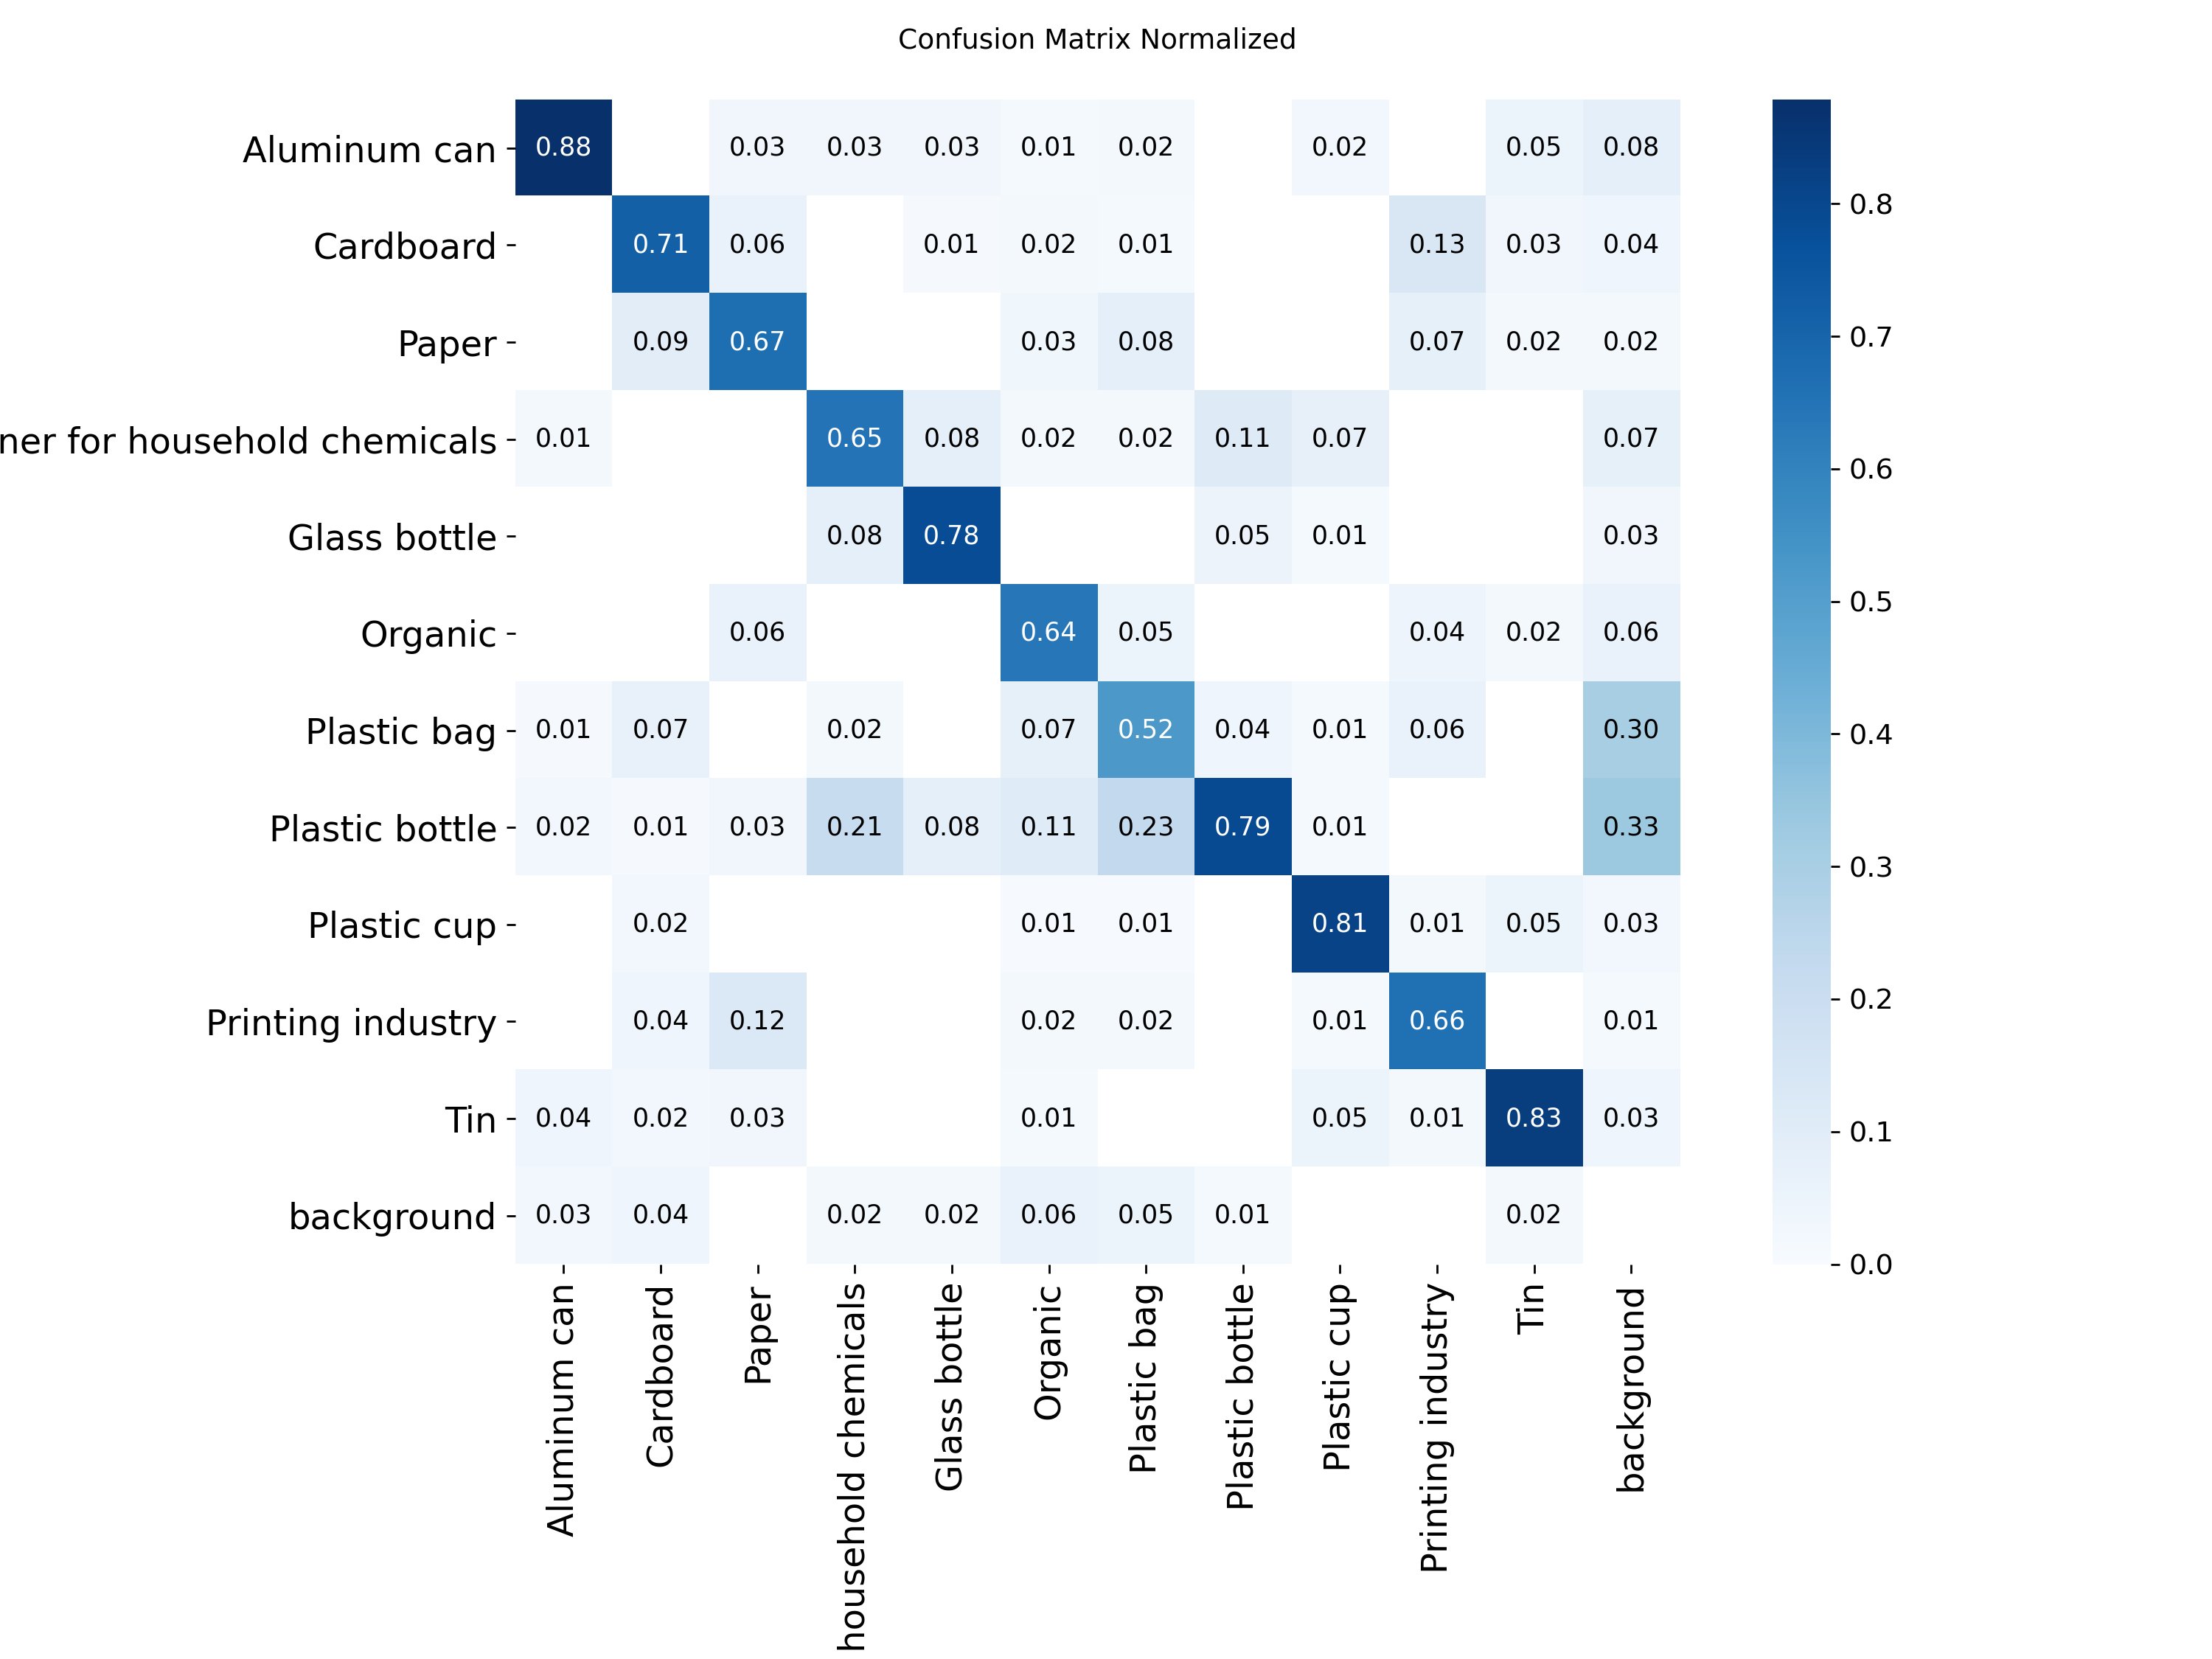

In [15]:
from IPython.display import Image, display
display(Image('/content/runs/detect/val/confusion_matrix_normalized.png', width=900))

In [16]:
t = model.val(data='/content/dataset_final/data.yaml', imgsz=640, split='test')
print('TEST mAP50 =', round(t.box.map50, 3))

f1 = m.box.f1_curve.mean(0)
print('Best confidence:', round(float(m.box.px[f1.argmax()]), 2), ' mean F1:', round(float(f1.max()), 2))

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 92 layers, 25,846,129 parameters, 0 gradients, 78.7 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 15.5±13.3 MB/s, size: 26.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/dataset_final/test/labels... 533 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 533/533 808.9it/s 0.7s
val: New cache created: /content/dataset_final/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 34/34 1.9it/s 18.2s
                   all        533        777       0.77      0.733      0.761      0.561
          Aluminum can        158        192      0.939      0.906      0.958      0.648
             Cardboard         61         75      0.835      0.867      0.885       0.67
       

In [17]:
import shutil, os
os.makedirs('/content/drive/MyDrive/garbage_project', exist_ok=True)
shutil.make_archive('/content/drive/MyDrive/garbage_project/dataset_final', 'zip', '/content', 'dataset_final')
shutil.copy('/content/garbage_project/v8m_final/weights/best.pt', '/content/drive/MyDrive/garbage_project/best_v8m_640.pt')
print('Saved')

Saved


In [18]:
from ultralytics import YOLO

model = YOLO('/content/garbage_project/v8m_final/weights/best.pt')
model.train(
    data='/content/dataset_final/data.yaml',
    epochs=20,              # change to 30 if you prefer
    imgsz=800,
    batch=8,
    patience=10,
    lr0=0.002,
    cos_lr=True,
    close_mosaic=5,
    workers=2,
    copy_paste=0.1,
    mixup=0.1,
    project='/content/drive/MyDrive/garbage_project',
    name='v8m_800',
    exist_ok=True,
)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/dataset_final/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, iou=0.7, kobj=1.0, line_width=None, lr0=0.002, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=/content/garbage_project/v8m_final/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=v8m_800, nbs=64, nms

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x786cf61edef0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.

In [19]:
from google.colab import files
files.download('/content/drive/MyDrive/garbage_project/backup/v8m_final/weights/best.pt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
from ultralytics import YOLO
BEST = '/content/drive/MyDrive/garbage_project/backup/v8m_final/weights/best.pt'
model = YOLO(BEST)

m = model.val(data='/content/dataset_final/data.yaml', imgsz=640, verbose=False)
f1 = m.box.f1_curve.mean(0)
print('Best confidence:', round(float(m.box.px[f1.argmax()]), 2))

t = model.val(data='/content/dataset_final/data.yaml', imgsz=640, split='test', verbose=False)
print('TEST mAP50 =', round(t.box.map50, 3))

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 92 layers, 25,846,129 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 500.0±296.5 MB/s, size: 9.9 KB)
val: Scanning /content/dataset_final/valid/labels.cache... 1064 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1064/1064 234.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 67/67 2.3it/s 29.2s
                   all       1064       1511      0.773      0.741      0.789      0.587
Speed: 1.0ms preprocess, 21.4ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to /content/runs/detect/val-3
Best confidence: 0.41
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 92 layers, 25,846,129 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 735.2±952.7 MB/s, size: 25.1

In [21]:
from google.colab import files
files.download('/content/drive/MyDrive/garbage_project/backup/v8m_final/weights/best.pt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>